**Title: Binary Classification using Logistic Regression on Bank Loan Dataset**

**Import libraries and load dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()

df = pd.read_csv('bankloan.csv.csv')

print(df.head())
print("Shape:", df.shape)

Saving bankloan.csv.csv to bankloan.csv.csv
   ID  Age  Experience  Income  ZIP.Code  Family  CCAvg  Education  Mortgage  \
0   1   25           1      49     91107       4    1.6          1         0   
1   2   45          19      34     90089       3    1.5          1         0   
2   3   39          15      11     94720       1    1.0          1         0   
3   4   35           9     100     94112       1    2.7          2         0   
4   5   35           8      45     91330       4    1.0          2         0   

   Personal.Loan  Securities.Account  CD.Account  Online  CreditCard  
0              0                   1           0       0           0  
1              0                   1           0       0           0  
2              0                   0           0       0           0  
3              0                   0           0       0           0  
4              0                   0           0       0           1  
Shape: (5000, 14)


**Inspect the dataset**

In [ ]:
# Dataset information
print(df.info())

# Statistical summary
print(df.describe())

# Missing values
print(df.isnull().sum())

# Duplicate records
print("Duplicates:", df.duplicated().sum())

# Target class distribution
print(df['Personal.Loan'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP.Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal.Loan       5000 non-null   int64  
 10  Securities.Account  5000 non-null   int64  
 11  CD.Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB
None
                ID          Age   Experience       

**Visualise class distribution**

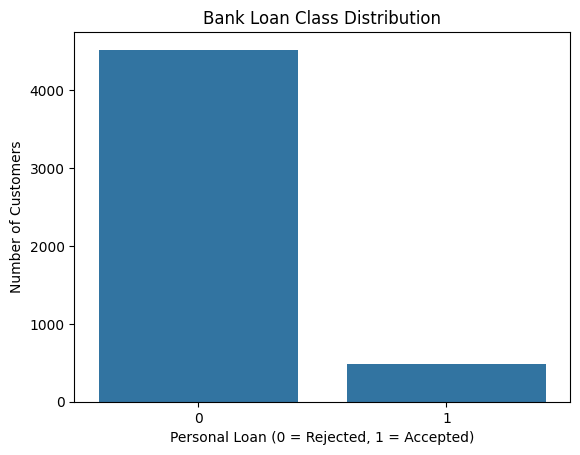

In [ ]:
sns.countplot(data=df, x='Personal.Loan')

plt.title('Bank Loan Class Distribution')
plt.xlabel('Personal Loan (0 = Rejected, 1 = Accepted)')
plt.ylabel('Number of Customers')
plt.show()

**Prepare the features**

In [ ]:
# Input features
X = df[['Age', 'Experience', 'Income',
        'Family', 'CCAvg', 'Education',
        'Mortgage', 'Securities.Account',
        'CD.Account', 'Online', 'CreditCard']]

# Target variable
y = df['Personal.Loan']

print(X.head())
print(y.head())

   Age  Experience  Income  Family  CCAvg  Education  Mortgage  \
0   25           1      49       4    1.6          1         0   
1   45          19      34       3    1.5          1         0   
2   39          15      11       1    1.0          1         0   
3   35           9     100       1    2.7          2         0   
4   35           8      45       4    1.0          2         0   

   Securities.Account  CD.Account  Online  CreditCard  
0                   1           0       0           0  
1                   1           0       0           0  
2                   0           0       0           0  
3                   0           0       0           0  
4                   0           0       0           1  
0    0
1    0
2    0
3    0
4    0
Name: Personal.Loan, dtype: int64


**Split the dataset**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training records: 4000
Testing records: 1000

Training class distribution:
Personal.Loan
0    3616
1     384
Name: count, dtype: int64

Testing class distribution:
Personal.Loan
0    904
1     96
Name: count, dtype: int64


**Understand the Sigmoid function**

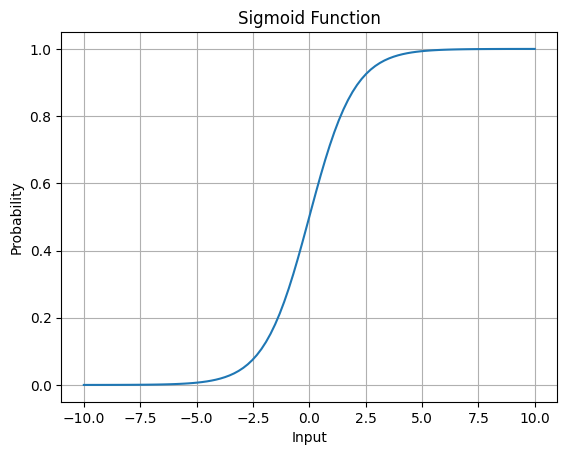

In [ ]:
x = np.linspace(-10, 10, 100)

y_sigmoid = 1 / (1 + np.exp(-x))

plt.plot(x, y_sigmoid)

plt.title('Sigmoid Function')
plt.xlabel('Input')
plt.ylabel('Probability')
plt.grid()
plt.show()

**Train Logistic Regression model**

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


**Display model coefficients and intercept**

In [9]:
log_model = model.named_steps['logistic']

print("Intercept:", log_model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_model.coef_[0]
})

print(coefficients)

Intercept: [-4.59108067]
               Feature  Coefficient
0                  Age    -0.338009
1           Experience     0.396314
2               Income     2.391154
3               Family     0.732153
4                CCAvg     0.234642
5            Education     1.428315
6             Mortgage     0.068060
7   Securities.Account    -0.284907
8           CD.Account     0.935894
9               Online    -0.332574
10          CreditCard    -0.496529


**Predict probabilities and class labels**

In [10]:
# Predicted probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Predicted class labels
y_pred = (y_prob >= 0.5).astype(int)

result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted Probability': y_prob,
    'Predicted Class': y_pred
})

print(result.head(10))

   Actual  Predicted Probability  Predicted Class
0       0               0.000154                0
1       1               0.879202                1
2       0               0.000176                0
3       0               0.029719                0
4       0               0.008734                0
5       0               0.006062                0
6       0               0.000985                0
7       0               0.001973                0
8       0               0.089920                0
9       0               0.033907                0


**Compare decision thresholds**

In [11]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

thresholds = [0.3, 0.5, 0.7]

for t in thresholds:

    pred = (y_prob >= t).astype(int)

    print("\nThreshold:", t)
    print("Predicted Positive:", sum(pred))
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred))


Threshold: 0.3
Predicted Positive: 107
Accuracy: 0.941
Precision: 0.6728971962616822
Recall: 0.75
F1 Score: 0.7093596059113301

Threshold: 0.5
Predicted Positive: 77
Accuracy: 0.955
Precision: 0.8311688311688312
Recall: 0.6666666666666666
F1 Score: 0.7398843930635838

Threshold: 0.7
Predicted Positive: 53
Accuracy: 0.951
Precision: 0.9433962264150944
Recall: 0.5208333333333334
F1 Score: 0.6711409395973155


**Confusion Matrix**

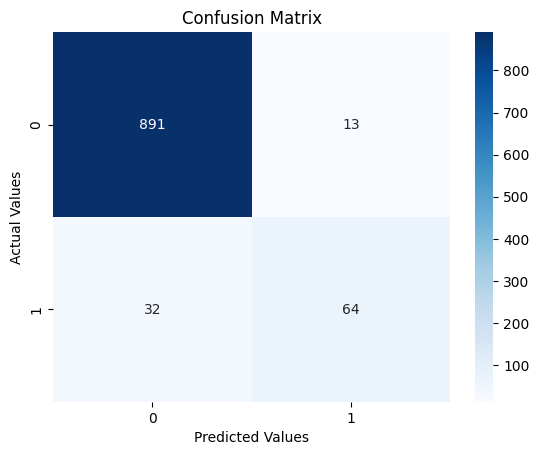

[[891  13]
 [ 32  64]]


In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

print(cm)

**Calculate classification metrics**

In [13]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

specificity = cm[0,0] / (cm[0,0] + cm[0,1])

roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.955
Precision: 0.8311688311688312
Recall: 0.6666666666666666
Specificity: 0.9856194690265486
F1 Score: 0.7398843930635838
ROC-AUC: 0.9634264380530975


**Classification report**

In [14]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       904
           1       0.83      0.67      0.74        96

    accuracy                           0.95      1000
   macro avg       0.90      0.83      0.86      1000
weighted avg       0.95      0.95      0.95      1000



**Compare with baseline model**

In [15]:
baseline_accuracy = y_test.value_counts(normalize=True).max()

print("Baseline Accuracy:", baseline_accuracy)
print("Logistic Regression Accuracy:", accuracy)

Baseline Accuracy: 0.904
Logistic Regression Accuracy: 0.955


**ROC curve and ROC-AUC**

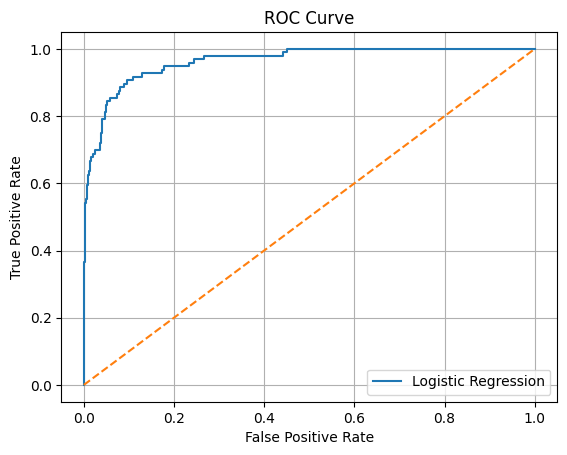

ROC-AUC: 0.9634264380530975


In [16]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC:", auc(fpr, tpr))

**Threshold comparison table**

In [17]:
threshold_results = []

for t in [0.3, 0.5, 0.7]:

    pred = (y_prob >= t).astype(int)

    threshold_results.append({
        'Threshold': t,
        'Predicted Positive': sum(pred),
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1 Score': f1_score(y_test, pred)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

   Threshold  Predicted Positive  Accuracy  Precision    Recall  F1 Score
0        0.3                 107     0.941   0.672897  0.750000  0.709360
1        0.5                  77     0.955   0.831169  0.666667  0.739884
2        0.7                  53     0.951   0.943396  0.520833  0.671141


**Visualise decision behaviour**

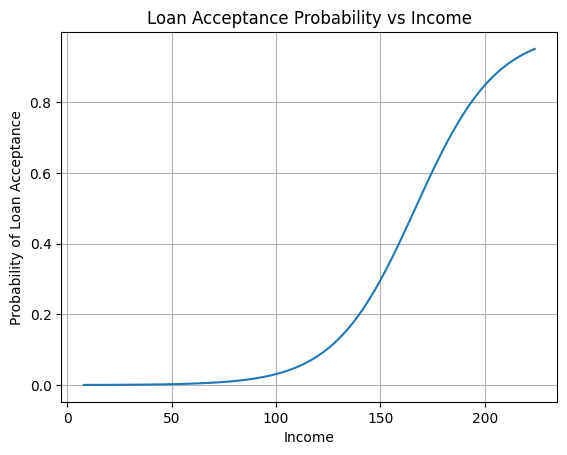

In [18]:
# Use Income as an example feature
income_values = np.linspace(
    X_train['Income'].min(),
    X_train['Income'].max(),
    100
)

sample = X_train.median().to_frame().T

probabilities = []

for income in income_values:
    sample['Income'] = income
    probabilities.append(model.predict_proba(sample)[0, 1])

plt.plot(income_values, probabilities)

plt.title('Loan Acceptance Probability vs Income')
plt.xlabel('Income')
plt.ylabel('Probability of Loan Acceptance')
plt.grid()
plt.show()

**Predict a new customer**

In [19]:
new_customer = pd.DataFrame([{
    'Age': 40,
    'Experience': 15,
    'Income': 100,
    'Family': 2,
    'CCAvg': 2.0,
    'Education': 2,
    'Mortgage': 0,
    'Securities.Account': 0,
    'CD.Account': 0,
    'Online': 1,
    'CreditCard': 0
}])

probability = model.predict_proba(new_customer)[0][1]

prediction = model.predict(new_customer)[0]

print("Loan Acceptance Probability:", probability)
print("Predicted Class:", prediction)

if prediction == 1:
    print("Customer may accept the personal loan.")
else:
    print("Customer may not accept the personal loan.")

Loan Acceptance Probability: 0.03206444018230774
Predicted Class: 0
Customer may not accept the personal loan.
